# MRI Software Resources

**Part:** Reference · **Reading time:** ~10 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** none

This is just a small sample of the MRI software available — tools focused on education and on general pulse-sequence design, simulation and reconstruction. The first list is the original author's selection; the following sections add Python (and a few other) packages that are widely used, each with one line on what it does, and the interactive web simulators referenced throughout the book together with their Python equivalents in this series.

Nothing in this notebook installs anything: the code cells only check which optional packages happen to be available, and use `mri_tools` for a small simulation. Follow the links (outside the notebook) for installation instructions.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. The original selection (education and general methods)

| Resource | What it is |
|---|---|
| https://github.com/kmjohnson3/Intro-to-MRI | Python Jupyter notebooks introducing MRI concepts, including advanced reconstructions (variational networks, compressed sensing) and distortion artifacts |
| https://github.com/mribri999/MRSignalsSeqs | MRI signals and systems course code and lectures (Brian Hargreaves), including builds of introductory MRI courses |
| https://github.com/markus-nilsson/mri-simulator | MATLAB simulator for educational purposes with nice net-magnetization illustrations |
| https://github.com/mikgroup/sigpy | Python package for signal processing, with powerful MRI reconstruction and MRI pulse-design tools |
| https://github.com/mrirecon/bart | Berkeley Advanced Reconstruction Toolbox: popular MRI reconstruction toolbox with many features for basic and advanced reconstructions |
| https://github.com/qMRLab/qMRLab | quantitative MRI processing methods, from $T_1$ and $T_2$ fitting to susceptibility mapping, diffusion and magnetization transfer |
| https://github.com/ISMRM/mrhub | MR-Hub: hub for the entire range of MRI software resources. Worth browsing, especially for advanced topics |

## 2. Python (and friends) for MRI — one line each

**Reconstruction and signal processing**

| Package | Language | What it does |
|---|---|---|
| **SigPy** (`sigpy`, `sigpy.mri`) — https://github.com/mikgroup/sigpy | Python (NumPy/CuPy) | linear operators, NUFFT, iterative solvers; `sigpy.mri` has SENSE/ESPIRiT, $\ell_1$-wavelet and TV reconstructions, coil-map estimation and sampling-pattern generators. Used for [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb), [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| **sigpy.mri.rf** (part of SigPy) | Python | RF pulse design: SLR, adiabatic, multiband/SMS and parallel-transmit pulses. Used for [E3](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb), [J3](../pass2_deep_dive/J3_Fun_with_RF_Pulses.ipynb) |
| **BART** — https://mrirecon.github.io/bart/ | C, with Python and MATLAB wrappers | command-line reconstruction toolbox: parallel imaging (ESPIRiT, GRAPPA-like), compressed sensing, non-Cartesian, model-based recon |
| **Gadgetron** — https://github.com/gadgetron/gadgetron | C++ (Python gadgets) | streaming reconstruction framework that can run online on scanners |
| **fastMRI** — https://github.com/facebookresearch/fastMRI (data: http://fastmri.med.nyu.edu) | Python (PyTorch) | large public raw-k-space datasets plus reference deep-learning reconstructions (U-Net, end-to-end VarNet) |
| **torchkbnufft** — https://github.com/mmuckley/torchkbnufft | Python (PyTorch) | differentiable non-uniform FFT for radial/spiral data in deep-learning pipelines |
| **FINUFFT** — https://github.com/flatironinstitute/finufft | C++ with Python/MATLAB/Julia interfaces | fast, accurate non-uniform FFT library |
| **MIRT** / **MIRT.jl** — https://github.com/JeffFessler/mirt, https://github.com/JeffFessler/MIRT.jl | MATLAB / Julia | Michigan Image Reconstruction Toolbox: NUFFT, iterative and regularized reconstruction (J. Fessler) |

**Pulse sequences and simulation**

| Package | Language | What it does |
|---|---|---|
| **Pulseq** — https://pulseq.github.io/ | MATLAB (+ file format) | open, vendor-neutral file format and toolbox for writing pulse sequences that can run on real scanners of several vendors |
| **PyPulseq** — https://github.com/imr-framework/pypulseq | Python | Python port of Pulseq: build sequences (RF, gradients, ADC events) in Python and export `.seq` files |
| **MRzero** — https://github.com/MRsources/MRzero-Core | Python (PyTorch) | fast, differentiable MR simulation of Pulseq sequences (phase-distribution graph), e.g. for sequence optimization |
| **KomaMRI.jl** — https://github.com/JuliaHealth/KomaMRI.jl | Julia | GPU-accelerated Bloch simulator with a GUI; reads Pulseq sequences and phantoms |
| **JEMRIS** — https://github.com/JEMRIS/jemris | C++ | general-purpose MRI simulator (Bloch equations, realistic coils and sequences) |
| Hargreaves Bloch simulator — http://mrsrl.stanford.edu/~brian/blochsim/ | MATLAB/C | the classic fast `bloch` function for simulating RF pulses and sequences |

**Raw data and image file formats**

| Package | Language | What it does |
|---|---|---|
| **ISMRMRD** — https://github.com/ismrmrd/ismrmrd, Python: https://github.com/ismrmrd/ismrmrd-python | C++/Python | vendor-neutral raw-data (k-space) format of the ISMRM, based on HDF5 |
| **twixtools** — https://github.com/pehses/twixtools | Python | reads Siemens raw-data (".dat"/twix) files |
| **pydicom** — https://github.com/pydicom/pydicom | Python | read/write DICOM, the clinical image format (with header metadata such as TE, TR, flip angle) |
| **nibabel** — https://nipy.org/nibabel/ | Python | read/write neuroimaging formats (NIfTI, MGH, …) with the voxel-to-world affine |
| **dcm2niix** — https://github.com/rordenlab/dcm2niix | C++ (command line) | converts DICOM series to NIfTI (+ JSON sidecar) |

**Image analysis (beyond the scope of this series)**

| Package | What it does |
|---|---|
| **DIPY** — https://dipy.org | diffusion MRI analysis in Python |
| **FSL**, **SPM**, **FreeSurfer** | neuroimaging analysis suites (registration, segmentation, fMRI/diffusion statistics) |
| **qMRLab** (above) | quantitative parameter mapping |

> **🧭 Intuition:** a typical research pipeline is *Pulseq/PyPulseq* (design the sequence) → scanner → *ISMRMRD/twixtools* (read raw data) → *SigPy/BART/Gadgetron* (reconstruct) → *pydicom/nibabel* (store and analyse images). *MRzero* or *KomaMRI* can replace the scanner with a simulation.

The next cell checks which of these optional Python packages are installed in the current environment (purely informational — the notebooks of this series only need NumPy, SciPy and Matplotlib).

In [2]:
import importlib.util

optional = {
    "sigpy": "SigPy (recon, sigpy.mri.rf pulse design)",
    "pypulseq": "PyPulseq (sequence design)",
    "MRzeroCore": "MRzero (differentiable simulation)",
    "ismrmrd": "ISMRMRD raw-data format",
    "twixtools": "Siemens raw-data reader",
    "pydicom": "DICOM",
    "nibabel": "NIfTI and other neuroimaging formats",
    "torchkbnufft": "PyTorch NUFFT",
    "finufft": "FINUFFT",
    "h5py": "HDF5 (used by ISMRMRD and fastMRI files)",
    "scipy": "SciPy (required by this series)",
    "ipywidgets": "ipywidgets (optional interactive cells)",
}
for module, description in optional.items():
    status = "installed" if importlib.util.find_spec(module) is not None else "not installed"
    print(f"{module:>13}: {status:13s} - {description}")

        sigpy: not installed - SigPy (recon, sigpy.mri.rf pulse design)
     pypulseq: not installed - PyPulseq (sequence design)
   MRzeroCore: not installed - MRzero (differentiable simulation)
      ismrmrd: not installed - ISMRMRD raw-data format
    twixtools: not installed - Siemens raw-data reader
      pydicom: not installed - DICOM
      nibabel: not installed - NIfTI and other neuroimaging formats
 torchkbnufft: not installed - PyTorch NUFFT
      finufft: not installed - FINUFFT
         h5py: installed     - HDF5 (used by ISMRMRD and fastMRI files)
        scipy: installed     - SciPy (required by this series)
   ipywidgets: installed     - ipywidgets (optional interactive cells)


Interpretation: whatever the output, every notebook in this series runs with only NumPy, SciPy and Matplotlib; the other packages are for going further.

## 3. Interactive web simulators used in the book

The original book links to two excellent browser-based simulators by Lars G. Hanson (DRCMR, Copenhagen). Keep using them — they are great for building intuition — and use the Python equivalents in this series to see the numbers behind them.

| Simulator | What you can do with it | Where it is used | Python equivalent here |
|---|---|---|---|
| **Bloch Simulator** — https://www.drcmr.dk/BlochSimulator/ | 3D view of magnetization vectors; lab vs rotating frame; hard pulses (90ₓ, 180ᵧ, …); relaxation; "Inhomogeneity" scene for dephasing and spin echoes | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb) | `mt.bloch_simulate`, `mt.plot_magnetization`, `mt.plot_magnetization_3d` |
| **CompassMR** — https://www.drcmr.dk/CompassMR/ | a compass needle in a field as an analogy for resonance, precession, detection with a coil, and relaxation | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) | `mt.bloch_rotate`, `mt.relax`; [RP3](../refreshers/RP3_Precession_and_Torque.ipynb) |
| Educational MR material by L. G. Hanson — https://www.drcmr.dk/mr | text and figures on spin physics (source of the spin-distribution figures) | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) | — |
| SpinBench — https://heartvista.ai/spinbench | interactive desktop RF-pulse/Bloch simulation tool, used to make the movies in "Fun with RF Pulses" | [J3](../pass2_deep_dive/J3_Fun_with_RF_Pulses.ipynb) | `mt.bloch_simulate` |

As an example, here is the Bloch Simulator's "Inhomogeneity" experiment (apply 90ₓ hard, wait, apply 180ᵧ hard) reproduced with `mt.bloch_simulate`: 41 isochromats with off-resonances spread over ±40 Hz dephase after the 90° pulse and re-phase into a spin echo after the 180° pulse. All simulation is in the rotating frame.

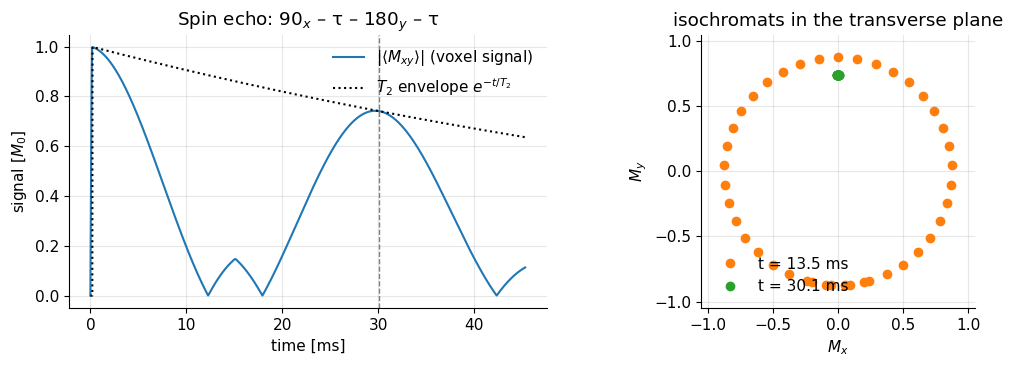

signal just before the 180: 0.079;  at the echo: 0.741;  T2 prediction exp(-2 tau/T2) = 0.741


In [3]:
dt = 20e-6                                  # time step [s]
df = np.linspace(-40, 40, 41)               # off-resonance of each isochromat [Hz]
T1, T2 = 1.0, 0.1                           # relaxation times [s]
T_90, T_180, tau = 0.2e-3, 0.4e-3, 15e-3    # pulse durations and 90-180 spacing [s]

b1_90 = mt.b1_for_flip(np.pi / 2, T_90)     # hard-pulse amplitudes [T]
b1_180 = mt.b1_for_flip(np.pi, T_180)
n90, n180 = round(T_90 / dt), round(T_180 / dt)
gap1 = round((tau - T_90 / 2 - T_180 / 2) / dt)   # pulse centre to pulse centre = tau
gap2 = round((tau + 15e-3) / dt)                  # run 15 ms past the expected echo
B1 = np.concatenate([np.full(n90, b1_90 + 0j),     # 90 deg about x  (real b1)
                     np.zeros(gap1, complex),
                     np.full(n180, 1j * b1_180),   # 180 deg about y (imaginary b1)
                     np.zeros(gap2, complex)])

t, M = mt.bloch_simulate(B1=B1, dt=dt, T1=T1, T2=T2, df=df)
Mxy = M[..., 0] + 1j * M[..., 1]            # (Nt+1, N_spins) complex transverse magnetization
signal = np.abs(Mxy.mean(axis=1))           # voxel signal = |average of all isochromats|
t_echo = (T_90 / 2 + 2 * tau)               # expected echo time measured from t = 0

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(t * 1e3, signal, label=r"$|\langle M_{xy}\rangle|$ (voxel signal)")
axs[0].plot(t * 1e3, np.exp(-(t - T_90 / 2) / T2) * (t > T_90), "k:", label=r"$T_2$ envelope $e^{-t/T_2}$")
axs[0].axvline(t_echo * 1e3, color="gray", ls="--", lw=1)
axs[0].set_xlabel("time [ms]"); axs[0].set_ylabel(r"signal [$M_0$]")
axs[0].set_title("Spin echo: 90$_x$ – τ – 180$_y$ – τ"); axs[0].legend(loc="upper right")
for tt, c in [(tau * 0.9, "C1"), (t_echo, "C2")]:
    i = np.argmin(abs(t - tt))
    axs[1].plot(Mxy[i].real, Mxy[i].imag, "o", color=c, label=f"t = {t[i]*1e3:.1f} ms")
axs[1].set_aspect("equal"); axs[1].set_xlim(-1.05, 1.05); axs[1].set_ylim(-1.05, 1.05)
axs[1].set_xlabel(r"$M_x$"); axs[1].set_ylabel(r"$M_y$"); axs[1].set_title("isochromats in the transverse plane")
axs[1].legend(loc="lower left")
plt.tight_layout(); plt.show()
print(f"signal just before the 180: {signal[np.argmin(abs(t - tau*0.9))]:.3f};  at the echo: {signal[np.argmin(abs(t - t_echo))]:.3f};  "
      f"T2 prediction exp(-2 tau/T2) = {np.exp(-2*tau/T2):.3f}")

Interpretation: after the 90° pulse the isochromats fan out and the voxel signal drops (left), they are spread around the circle just before the 180° pulse (right, orange); at $t\approx2\tau$ they line up again (green) and the signal recovers to the $T_2$ envelope — the off-resonance dephasing ($T_2'$) is refocused, the $T_2$ loss is not. This is exactly what the Bloch Simulator's "Inhomogeneity" scene shows, now with numbers you can change.

## Key takeaways

* For learning: the drcmr.dk Bloch Simulator and CompassMR (intuition) plus `mri_tools` (numbers) cover everything in this series.
* For research in Python: SigPy (recon + `sigpy.mri.rf` pulse design), BART, PyPulseq/Pulseq (sequences), MRzero/KomaMRI (simulation), ISMRMRD/twixtools (raw data), pydicom/nibabel (images).
* MR-Hub (ISMRM) is the best starting point to find more specialized tools.

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Software_Resources".
Changes: kept the original list; added one-line descriptions of widely used reconstruction, sequence-design, simulation and file-format packages, the web simulators referenced in the book with their `mri_tools` equivalents, an installed-package check, and a Python reproduction of the Bloch Simulator's spin-echo experiment.*